# 学习目标

- 解释时间复杂度为什么关注输入规模增大时的变化趋势
- 使用大O记号描述常见算法的时间复杂度
- 根据循环、嵌套结构和规模缩减分析 Python 程序
- 比较算法并选择更合适的方案

## 1. 从查找问题开始

在一组无序数据中查找目标值。最坏情况下，程序必须检查列表中的每一个元素。

In [ ]:
def contains(values, target):
    for value in values:
        if value == target:
            return True
    return False

values = [3, 8, 2, 5]
print(contains(values, 2))

True


## 2. 什么是时间复杂度

时间复杂度描述算法的基本操作执行次数如何随输入规模 $n$ 增长。

$$
T(n)=\text{算法基本操作的执行次数}
$$

它不等于某台电脑上的实际运行秒数。时间复杂度关注输入足够大时，工作量增长得有多快。

### 基本操作的执行次数

基本操作是算法中反复执行、能够代表主要工作量的一步。下面把 `total += value` 作为基本操作并进行计数。

In [46]:
def count_additions(n):
    count = 0
    total = 0
    for value in range(n):
        total += value      # 基本操作
        count += 1
    return count

for n in (3, 5, 10):
    print(f"n={n:>2}, 基本操作执行次数={count_additions(n)}")

n= 3, 基本操作执行次数=3
n= 5, 基本操作执行次数=5
n=10, 基本操作执行次数=10


列表包含 $n$ 个元素，基本操作执行 $n$ 次，因此：

$$
T(n)=n=O(n)
$$

实际运行时间还会受 CPU、内存、操作系统和解释器等因素影响。大 O 分析把这些因素暂时分离，只比较算法的增长趋势。

## 3. 大 O 记号与化简

若存在常数 $c$ 和 $n_0$，当 $n\ge n_0$ 时满足：

$$
0\le T(n)\le c\,f(n)
$$

则记作 $T(n)=O(f(n))$。

常用化简规则：

- 忽略常数因子，例如 $3n=O(n)$
- 忽略低阶项，例如 $n^2+20n+1=O(n^2)$
- 连续代码块的复杂度相加，最后保留增长最快的一项

## 4. 常见增长率

| 时间复杂度 | 名称 | 典型例子 |
|---|---|---|
| $O(1)$ | 常数时间 | 按下标访问列表元素 |
| $O(\log n)$ | 对数时间 | 二分查找 |
| $O(n)$ | 线性时间 | 遍历列表 |
| $O(n\log n)$ | 线性对数时间 | 高效排序 |
| $O(n^2)$ | 平方时间 | 简单的双重比较 |
| $O(2^n)$ | 指数时间 | 枚举所有子集 |

修改下面代码中的 `max_n`，重新运行即可比较不同输入规模下的增长率。

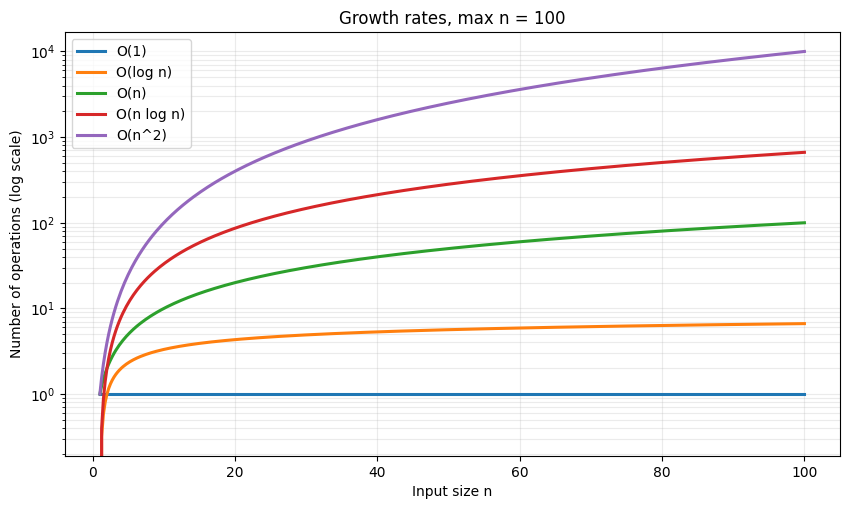

n = 100
log2(n)      = 6.64
n             = 100
n log2(n)     = 664.39
n^2           = 10,000


In [47]:
import math
import matplotlib.pyplot as plt

max_n = 100  # 修改这里，例如 10、100、1000、10000
sample_count = 400
n_values = [1 + (max_n - 1) * i / (sample_count - 1) for i in range(sample_count)]

curves = {
    "O(1)": [1 for n in n_values],
    "O(log n)": [math.log2(n) for n in n_values],
    "O(n)": n_values,
    "O(n log n)": [n * math.log2(n) for n in n_values],
    "O(n^2)": [n ** 2 for n in n_values],
}

plt.figure(figsize=(10, 5.5))
for label, results in curves.items():
    plt.plot(n_values, results, linewidth=2.2, label=label)

plt.yscale("log")
plt.xlabel("Input size n")
plt.ylabel("Number of operations (log scale)")
plt.title(f"Growth rates, max n = {max_n}")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.show()

print(f"n = {max_n}")
print(f"log2(n)      = {math.log2(max_n):,.2f}")
print(f"n             = {max_n:,}")
print(f"n log2(n)     = {max_n * math.log2(max_n):,.2f}")
print(f"n^2           = {max_n ** 2:,}")

## 5. 单层循环：$O(n)$

In [48]:
def sum_values(values):
    total = 0
    for value in values:
        total += value
    return total

print(sum_values([1, 2, 3, 4, 5]))

15


循环执行 $n$ 次，每次只做常数工作，因此：

$$
T(n)=an+b=O(n)
$$

## 6. 嵌套循环：$O(n^2)$

In [49]:
def has_duplicate(values):
    comparisons = 0
    for i in range(len(values)):
        for j in range(i + 1, len(values)):
            comparisons += 1
            if values[i] == values[j]:
                return True, comparisons
    return False, comparisons

print(has_duplicate([4, 1, 7, 4]))
print(has_duplicate([1, 2, 3, 4, 5]))

(True, 3)
(False, 10)


最坏情况下的比较次数为：

$$
\frac{n(n-1)}{2}
$$

最高阶项是 $n^2$，因此时间复杂度为 $O(n^2)$。

## 7. 连续代码块：相加后取最大项

In [50]:
def sequential_blocks(n):
    first_count = 0
    second_count = 0

    for _ in range(n):          # O(n)
        first_count += 1

    for _ in range(n):          # O(n^2)
        for _ in range(n):
            second_count += 1

    return first_count, second_count

print(sequential_blocks(5))

(5, 25)


$$
T(n)=O(n)+O(n^2)=O(n^2)
$$

## 8. 对半缩小：$O(\log n)$

In [51]:
def binary_search(values, target):
    left, right = 0, len(values) - 1
    comparisons = 0
    while left <= right:
        comparisons += 1
        middle = (left + right) // 2
        if values[middle] == target:
            return middle, comparisons
        if values[middle] < target:
            left = middle + 1
        else:
            right = middle - 1
    return -1, comparisons

values = list(range(1, 1025))
print(binary_search(values, 1000))

(999, 7)


每次比较后，搜索范围缩小为原来的一半：

$$
\frac{n}{2^k}=1 \quad\Rightarrow\quad k=\log_2 n
$$

二分查找要求输入序列已经排序。如果数据无序且只查询一次，线性查找通常更合适。

## 9. 最好、最坏与平均情况

以线性查找为例：

| 情况 | 目标位置 | 时间复杂度 |
|---|---|---|
| 最好情况 | 第一个元素 | $O(1)$ |
| 最坏情况 | 最后一个元素或不存在 | $O(n)$ |
| 平均情况 | 中间附近 | $O(n)$ |

讨论大 O 时通常关注最坏情况，因为它给出性能上界。

## 10. 递归示例

In [52]:
def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n - 1)

print(factorial(5))

120


递归深度为 $n$，每一层只做常数工作：

- 时间复杂度：$O(n)$
- 额外空间复杂度：$O(n)$，空间用于递归调用栈

## 11. 易混淆点

两个循环不一定是 $O(n^2)$。下面两个循环先后执行，总次数为 $n+n=2n$。

In [53]:
n = 5
count = 0

for _ in range(n):
    count += 1

for _ in range(n):
    count += 1

print(f"总执行次数 = {count}")

总执行次数 = 10


$$
O(n)+O(n)=O(n)
$$

只有循环相互嵌套且内外层规模都与 $n$ 成正比时，次数才会相乘。

## 12. 课堂练习

先判断下面代码的时间复杂度，再运行代码观察不同 $n$ 对应的计数结果。

In [54]:
def count_pairs(n):
    count = 0
    for i in range(n):
        for j in range(i, n, 2):
            count += 1
    return count

for n in (10, 20, 40, 80):
    print(f"n={n:>2}, count={count_pairs(n):>4}")

n=10, count=  30
n=20, count= 110
n=40, count= 420
n=80, count=1640


答案是 $O(n^2)$。内层循环的步长虽然为 2，但执行次数仍与 $n$ 成正比，常数不会改变复杂度等级。

## 13. 用集合改进重复元素检查

集合的平均查找时间为 $O(1)$。遍历列表一次，同时记录已经出现的元素，可把平均时间复杂度从 $O(n^2)$ 降为 $O(n)$。

In [55]:
def has_duplicate_fast(values):
    seen = set()
    for value in values:
        if value in seen:
            return True
        seen.add(value)
    return False

print(has_duplicate_fast([4, 1, 7, 4]))
print(has_duplicate_fast([1, 2, 3, 4]))

True
False


## 小结

- 时间复杂度描述算法工作量随输入规模增长的趋势
- 顺序结构的复杂度相加，嵌套结构的次数通常相乘
- 每次将规模缩小一半，常见复杂度为 $O(\log n)$
- 大 O 忽略常数因子和低阶项，保留主导增长项

$$
O(1)<O(\log n)<O(n)<O(n\log n)<O(n^2)<O(2^n)
$$